Billy York

06/01/2026

# Setting Up PostgreSQL and the Simulator

### Running containers

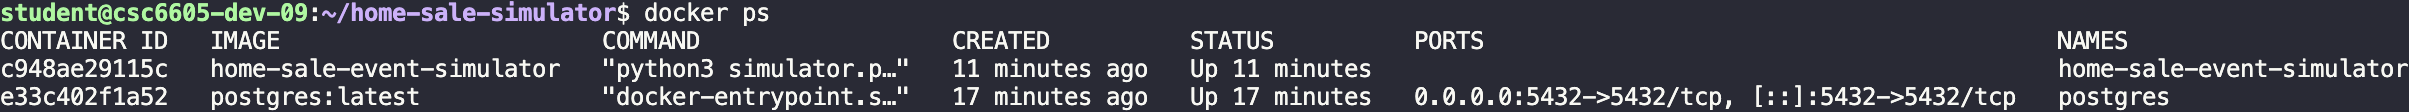

### Table schema

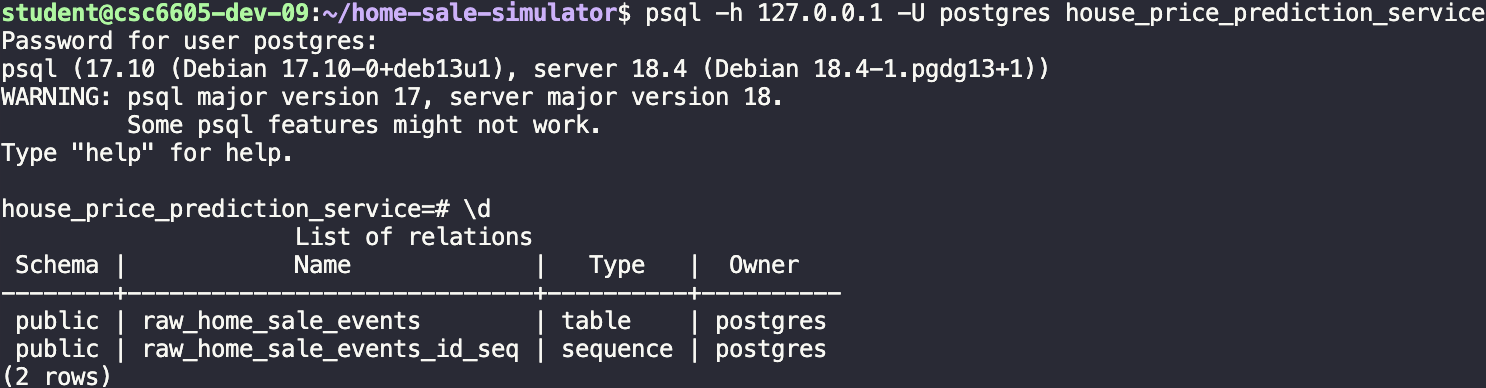

### Sample records

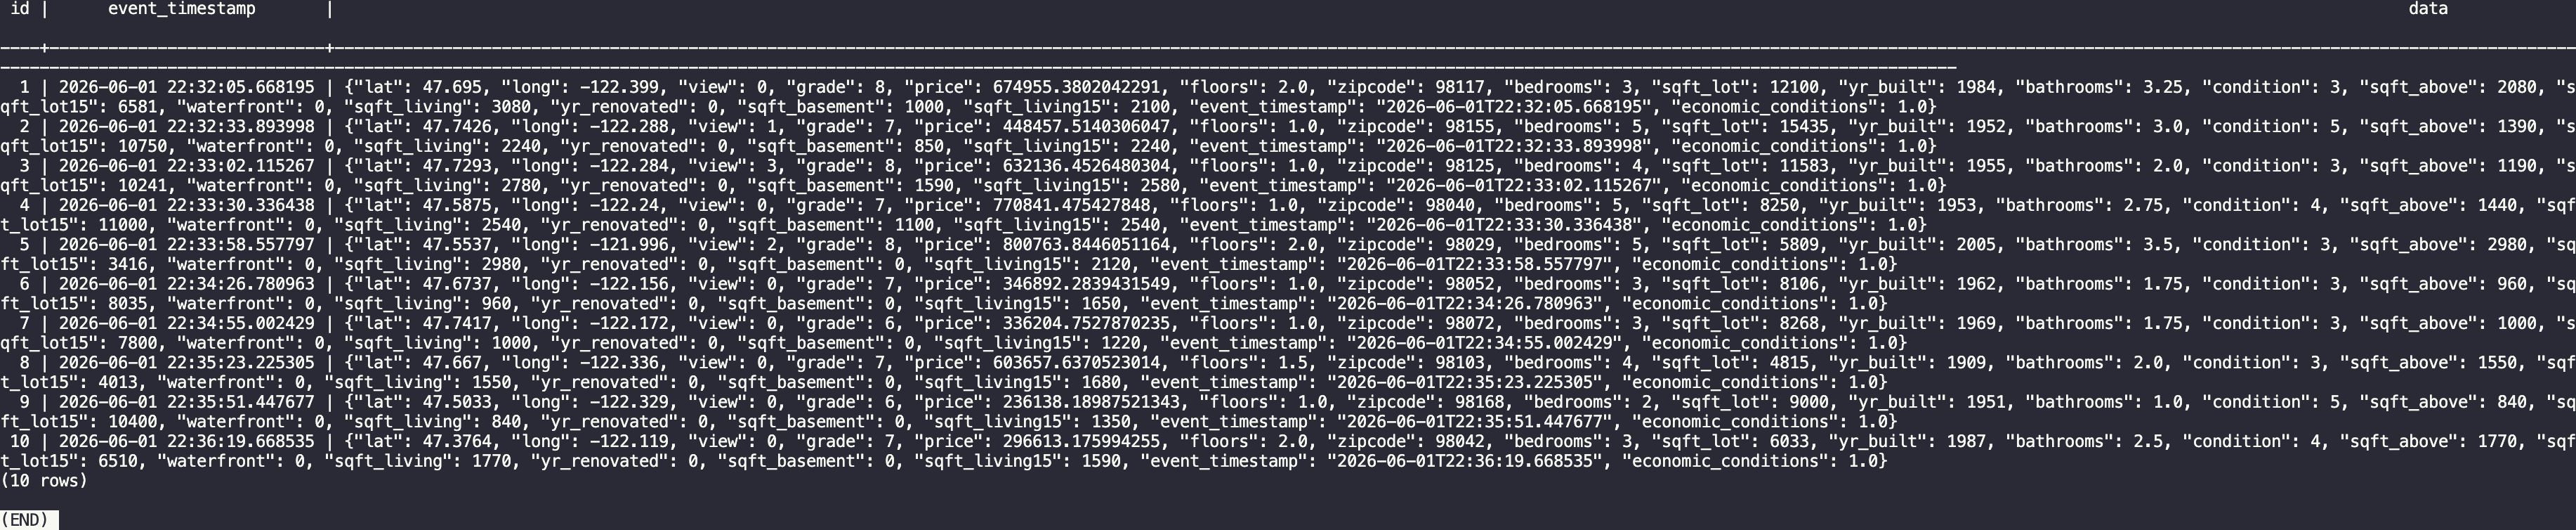

In [1]:
from matplotlib import pyplot
import seaborn as sns
import pandas as pd
import psycopg
from psycopg.rows import dict_row

In [2]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [3]:
conn_string = 'postgresql://{}:{}@{}:5432/house_price_prediction_service'.format(user, password, host)
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT id, event_timestamp, data FROM raw_home_sale_events;')
        # rows will be a list of dicts with the keys 'id', 'event_timestamp', and 'data'
        rows = cur.fetchall()

In [4]:
# Add all the ids to the inner data dictionaries and extract them
json_events = []
for row in rows:
    event = row['data']
    event['id'] = row['id']
    event['event_timestamp'] = row['event_timestamp']
    json_events.append(event)
df = pd.DataFrame.from_records(json_events)

In [5]:
df['offset_timestamp'] = df['event_timestamp'] + pd.Timedelta(hours=2)
grouped = df.groupby(df['offset_timestamp'].dt.hour)
hours = grouped.groups.keys()
print(hours)
grouped = grouped.count()
grouped.head(10)

dict_keys([0, 1, 2, 3, 4])


,lat,long,view,grade,price,floors,zipcode,bedrooms,sqft_lot,yr_built,...,sqft_lot15,waterfront,sqft_living,yr_renovated,sqft_basement,sqft_living15,event_timestamp,economic_conditions,id,offset_timestamp
offset_timestamp,,,,,,,,,,,,,,,,,,,,,
0,60,60,60,60,60,60,60,60,60,60,...,60,60,60,60,60,60,60,60,60,60
1,127,127,127,127,127,127,127,127,127,127,...,127,127,127,127,127,127,127,127,127,127
2,128,128,128,128,128,128,128,128,128,128,...,128,128,128,128,128,128,128,128,128,128
3,128,128,128,128,128,128,128,128,128,128,...,128,128,128,128,128,128,128,128,128,128
4,109,109,109,109,109,109,109,109,109,109,...,109,109,109,109,109,109,109,109,109,109


[Text(0.5, 1.0, 'Number of House Records Added Each Hour'),
 Text(0.5, 0, 'Hours Since Starting Simulator'),
 Text(0, 0.5, 'Number of Houses Added'),

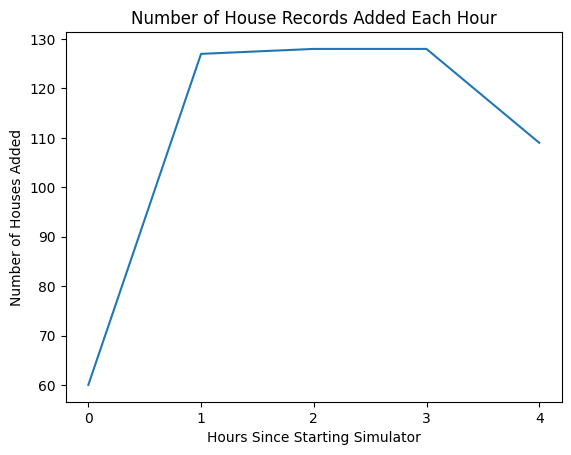

In [6]:
sns.lineplot(x=hours, y=grouped['id']).set(title='Number of House Records Added Each Hour', xlabel='Hours Since Starting Simulator', ylabel='Number of Houses Added', xticks=list(range(0, 5)))